In [1]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter



IVF-Zygote:
  Reference: IVF-Zygote-Bulk
  Single cells: 31

IVF-2C:
  Reference: IVF-2C-Pseudobulk
  Single cells: 109

IVF-4C:
  Reference: IVF-4C-Bulk
  Single cells: 210

PA-MII:
  Reference: PA-MII-Pseudobulk
  Single cells: 35

PA-2C:
  Reference: PA-2C-Pseudobulk
  Single cells: 108

PA-4C:
  Reference: PA-4C-Bulk
  Single cells: 195


JSD summary
IVF-2C          n=109  mean=0.01325  SD=0.01984
IVF-4C          n=210  mean=0.00426  SD=0.00531
IVF-Zygote      n= 30  mean=0.03915  SD=0.02264
PA-2C           n=108  mean=0.01241  SD=0.01325
PA-4C           n=195  mean=0.00381  SD=0.00416
PA-MII          n= 35  mean=0.01063  SD=0.03621


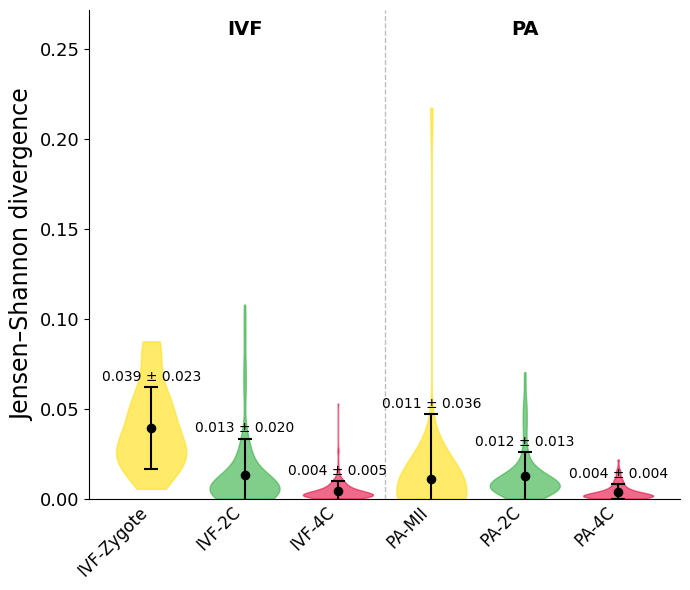

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from scipy.spatial.distance import jensenshannon


# ============================================================
# Matplotlib settings
# ============================================================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'


# ============================================================
# 1. Read IVF data
# ============================================================
ivf = pd.read_csv(
    'IVF_350_Ps_curve_new.txt',
    sep='\t',
    index_col=0,
    encoding='utf-8-sig'
)


# ============================================================
# Clean IVF IDs
# ============================================================
ivf.index = (
    ivf.index
    .astype(str)
    .str.replace('\ufeff', '', regex=False)
    .str.replace('\r', '', regex=False)
    .str.replace('\n', '', regex=False)
    .str.strip()
)


# ============================================================
# Convert IVF genomic-distance columns
#
# "ID" is actually genomic distance = 0
# ============================================================
ivf_distance_columns = []

for col in ivf.columns:

    if col == 'ID':
        ivf_distance_columns.append(0.0)

    else:
        ivf_distance_columns.append(float(col))


ivf.columns = ivf_distance_columns

ivf = ivf.sort_index(axis=1)


# ============================================================
# 2. Read PA data
# ============================================================
pa = pd.read_csv(
    'PA_334_Ps_curve_new.txt',
    sep='\t',
    encoding='utf-8-sig'
)


# ============================================================
# Clean PA IDs
# ============================================================
pa['ID'] = (
    pa['ID']
    .astype(str)
    .str.replace('\ufeff', '', regex=False)
    .str.replace('\r', '', regex=False)
    .str.replace('\n', '', regex=False)
    .str.strip()
)


# ============================================================
# PA genomic-distance columns
# ============================================================
pa_x = np.array(
    pa.columns[1:],
    dtype=float
)


# ============================================================
# 3. Define groups
# ============================================================

group_config = {

    # --------------------------------------------------------
    # IVF
    # --------------------------------------------------------
    'IVF-Zygote': {
        'condition': 'IVF',
        'cell_prefix': 'IVF-1C',
        'reference': 'IVF-Zygote-Bulk'
    },

    'IVF-2C': {
        'condition': 'IVF',
        'cell_prefix': 'IVF-2-',
        'reference': 'IVF-2C-Pseudobulk'
    },

    'IVF-4C': {
        'condition': 'IVF',
        'cell_prefix': 'IVF-4-',
        'reference': 'IVF-4C-Bulk'
    },

    # --------------------------------------------------------
    # PA
    # --------------------------------------------------------
    'PA-MII': {
        'condition': 'PA',
        'cell_prefix': 'PA-MII',
        'reference': 'PA-MII-Pseudobulk'
    },

    'PA-2C': {
        'condition': 'PA',
        'cell_prefix': 'PA-2C',
        'reference': 'PA-2C-Pseudobulk'
    },

    'PA-4C': {
        'condition': 'PA',
        'cell_prefix': 'PA-4C',
        'reference': 'PA-4C-Bulk'
    }
}


# ============================================================
# 4. JSD calculation function
# ============================================================
def calculate_jsd(single_curve, reference_curve):
    """
    Calculate Jensen-Shannon divergence between
    two P(s) curves.

    The curves are normalized to probability distributions.

    base=2:
        JSD range = 0 to 1
    """

    single_curve = np.asarray(
        single_curve,
        dtype=float
    )

    reference_curve = np.asarray(
        reference_curve,
        dtype=float
    )

    # --------------------------------------------------------
    # Check length
    # --------------------------------------------------------
    if len(single_curve) != len(reference_curve):
        raise ValueError(
            'Curve lengths are different.'
        )

    # --------------------------------------------------------
    # Replace invalid values
    # --------------------------------------------------------
    valid = (
        np.isfinite(single_curve)
        &
        np.isfinite(reference_curve)
    )

    single_curve = single_curve[valid]
    reference_curve = reference_curve[valid]

    # --------------------------------------------------------
    # P(s) should be non-negative
    # --------------------------------------------------------
    single_curve = np.clip(
        single_curve,
        a_min=0,
        a_max=None
    )

    reference_curve = np.clip(
        reference_curve,
        a_min=0,
        a_max=None
    )

    # --------------------------------------------------------
    # Normalize to probability distributions
    # --------------------------------------------------------
    single_sum = single_curve.sum()
    reference_sum = reference_curve.sum()

    if single_sum <= 0 or reference_sum <= 0:
        return np.nan

    p = single_curve / single_sum
    q = reference_curve / reference_sum

    # --------------------------------------------------------
    # Jensen-Shannon distance
    #
    # scipy returns sqrt(JSD)
    #
    # Therefore square it to obtain JSD itself.
    # base=2 -> JSD range = 0-1
    # --------------------------------------------------------
    js_distance = jensenshannon(
        p,
        q,
        base=2
    )

    jsd = js_distance ** 2

    return jsd


# ============================================================
# 5. Calculate IVF JSD
# ============================================================

ivf_jsd_results = []


for group, config in group_config.items():

    if config['condition'] != 'IVF':
        continue

    reference_id = config['reference']

    # --------------------------------------------------------
    # Check reference
    # --------------------------------------------------------
    if reference_id not in ivf.index:

        print(
            f'WARNING: {reference_id} not found in IVF data!'
        )

        continue

    # --------------------------------------------------------
    # Reference curve
    # --------------------------------------------------------
    reference_curve = (
        ivf.loc[reference_id]
        .values
        .astype(float)
    )

    # --------------------------------------------------------
    # Find single cells
    # --------------------------------------------------------
    prefix = config['cell_prefix']

    single_cell_ids = [
        curve_id
        for curve_id in ivf.index
        if curve_id.startswith(prefix)
    ]

    print(
        f'\n{group}:'
    )

    print(
        f'  Reference: {reference_id}'
    )

    print(
        f'  Single cells: {len(single_cell_ids)}'
    )

    # --------------------------------------------------------
    # Calculate JSD
    # --------------------------------------------------------
    for curve_id in single_cell_ids:

        single_curve = (
            ivf.loc[curve_id]
            .values
            .astype(float)
        )

        if not np.isfinite(single_curve).all():
            continue

        if not np.isfinite(reference_curve).all():
            continue

        try:

            jsd = calculate_jsd(
                single_curve,
                reference_curve
            )

            if np.isfinite(jsd):

                ivf_jsd_results.append({
                    'Condition': 'IVF',
                    'Stage': group,
                    'Cell_ID': curve_id,
                    'Reference': reference_id,
                    'JSD': jsd
                })

        except Exception as e:

            print(
                f'Error: {curve_id} -> {e}'
            )


# ============================================================
# 6. Calculate PA JSD
# ============================================================

pa_jsd_results = []


for group, config in group_config.items():

    if config['condition'] != 'PA':
        continue

    reference_id = config['reference']

    # --------------------------------------------------------
    # Check reference
    # --------------------------------------------------------
    reference_rows = pa[
        pa['ID'] == reference_id
    ]

    if reference_rows.empty:

        print(
            f'WARNING: {reference_id} not found in PA data!'
        )

        continue

    # --------------------------------------------------------
    # Reference curve
    # --------------------------------------------------------
    reference_curve = (
        reference_rows.iloc[0, 1:]
        .values
        .astype(float)
    )

    # --------------------------------------------------------
    # Find single cells
    # --------------------------------------------------------
    prefix = config['cell_prefix']

    single_cell_rows = pa[
        pa['ID'].str.startswith(prefix)
    ]

    print(
        f'\n{group}:'
    )

    print(
        f'  Reference: {reference_id}'
    )

    print(
        f'  Single cells: {len(single_cell_rows)}'
    )

    # --------------------------------------------------------
    # Calculate JSD
    # --------------------------------------------------------
    for _, row in single_cell_rows.iterrows():

        curve_id = row['ID']

        single_curve = (
            row.iloc[1:]
            .values
            .astype(float)
        )

        if not np.isfinite(single_curve).all():
            continue

        if not np.isfinite(reference_curve).all():
            continue

        try:

            jsd = calculate_jsd(
                single_curve,
                reference_curve
            )

            if np.isfinite(jsd):

                pa_jsd_results.append({
                    'Condition': 'PA',
                    'Stage': group,
                    'Cell_ID': curve_id,
                    'Reference': reference_id,
                    'JSD': jsd
                })

        except Exception as e:

            print(
                f'Error: {curve_id} -> {e}'
            )


# ============================================================
# 7. Combine IVF + PA
# ============================================================

jsd_df = pd.DataFrame(
    ivf_jsd_results + pa_jsd_results
)


# ============================================================
# 8. Print summary
# ============================================================

print('\n')
print('=' * 75)
print('JSD summary')
print('=' * 75)


summary = (
    jsd_df
    .groupby(['Condition', 'Stage'])['JSD']
    .agg(
        n='count',
        mean='mean',
        sd='std'
    )
    .reset_index()
)


for _, row in summary.iterrows():

    print(
        f"{row['Stage']:15s} "
        f"n={int(row['n']):3d}  "
        f"mean={row['mean']:.5f}  "
        f"SD={row['sd']:.5f}"
    )


print('=' * 75)


# ============================================================
# 9. Save JSD values
# ============================================================

jsd_df.to_csv(
    'IVF_PA_Ps_curve_JSD_values.txt',
    sep='\t',
    index=False
)


summary.to_csv(
    'IVF_PA_Ps_curve_JSD_summary.txt',
    sep='\t',
    index=False
)


# ============================================================
# 10. Plot
# ============================================================

plot_order = [
    'IVF-Zygote',
    'IVF-2C',
    'IVF-4C',
    'PA-MII',
    'PA-2C',
    'PA-4C'
]


# Colors
plot_colors = [
    '#ffe119',
    '#3cb44b',
    '#e6194b',
    '#ffe119',
    '#3cb44b',
    '#e6194b'
]


data_to_plot = []

for stage in plot_order:

    values = (
        jsd_df[
            jsd_df['Stage'] == stage
        ]['JSD']
        .values
    )

    data_to_plot.append(
        values
    )


# ============================================================
# Figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 6)
)


# ============================================================
# Violin plots
# ============================================================

parts = ax.violinplot(
    data_to_plot,
    positions=np.arange(
        len(plot_order)
    ),
    widths=0.75,
    showmeans=False,
    showmedians=False,
    showextrema=False
)


# ============================================================
# Violin colors
# ============================================================

for body, color in zip(
    parts['bodies'],
    plot_colors
):

    body.set_facecolor(
        color
    )

    body.set_edgecolor(
        color
    )

    body.set_alpha(
        0.65
    )


# ============================================================
# Mean ± SD
# ============================================================

for i, values in enumerate(
    data_to_plot
):

    values = np.asarray(
        values,
        dtype=float
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:
        continue

    mean = np.mean(values)
    sd = np.std(
        values,
        ddof=1
    )

    # --------------------------------------------------------
    # Mean point
    # --------------------------------------------------------
    ax.scatter(
        i,
        mean,
        color='black',
        s=35,
        zorder=10
    )

    # --------------------------------------------------------
    # SD error bar
    # --------------------------------------------------------
    ax.errorbar(
        i,
        mean,
        yerr=sd,
        fmt='none',
        ecolor='black',
        elinewidth=1.5,
        capsize=5,
        capthick=1.5,
        zorder=9
    )

    # --------------------------------------------------------
    # Mean ± SD text
    # --------------------------------------------------------
    ax.text(
        i,
        mean + sd + 0.002,
        f'{mean:.3f} ± {sd:.3f}',
        ha='center',
        va='bottom',
        fontsize=10
    )


# ============================================================
# X axis
# ============================================================

ax.set_xticks(
    np.arange(
        len(plot_order)
    )
)

ax.set_xticklabels(
    plot_order,
    fontsize=12,
    rotation=45,
    ha='right'
)


# ============================================================
# Y axis
# ============================================================

ax.set_ylabel(
    'Jensen–Shannon divergence',
    fontsize=17
)

ax.tick_params(
    axis='y',
    labelsize=13
)


# ============================================================
# Y range
# ============================================================

max_value = max(
    [
        np.nanmax(v)
        for v in data_to_plot
        if len(v) > 0
    ]
)

ax.set_ylim(
    0,
    max_value * 1.25
)


# ============================================================
# IVF / PA separation
# ============================================================

ax.axvline(
    2.5,
    color='gray',
    linestyle='--',
    linewidth=1,
    alpha=0.5
)


# ============================================================
# Labels for IVF / PA
# ============================================================

y_top = ax.get_ylim()[1]

ax.text(
    1,
    y_top * 0.98,
    'IVF',
    ha='center',
    va='top',
    fontsize=14,
    fontweight='bold'
)

ax.text(
    4,
    y_top * 0.98,
    'PA',
    ha='center',
    va='top',
    fontsize=14,
    fontweight='bold'
)


# ============================================================
# Clean appearance
# ============================================================

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.tick_params(
    axis='x',
    length=0
)


# ============================================================
# Layout
# ============================================================

plt.tight_layout()


# ============================================================
# Save
# ============================================================

plt.savefig(
    'IVF_PA_Ps_curve_JSD_violin.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)

plt.savefig(
    'IVF_PA_Ps_curve_JSD_violin.png',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)


# ============================================================
# Show
# ============================================================

plt.show()